In [1]:
!pip install -U tbparse

Looking in indexes: https://pypi.python.org/simple/
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 5.5 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 21.2 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: tensorboard-data-server
    Found existing installation: tensorboard-data-server 0.6.1
    Uninstalling tensorboard-data-server-0.6.1:
      Successfully uninstalled tensorboard-data-server-0.6.1
  Attempting uninstall: tensorboard
    Found existing installation: tensorboard 2.11.1
    Uninstalling tensorboard-2.11.1:
      Successfully uninstalled tensorboard-2.11.1

[notice] A new release of pip is available: 24.0 -> 25.1.1
[notice] To update, run: pip install --upgrade pip


In [57]:
import numpy as np
from tbparse import SummaryReader
import matplotlib.pyplot as plt
import seaborn as sns
import json

In [73]:
var = "aro_t2m_2m"

## RMSE

In [74]:


# Read and parse the JSON file
with open("/data/Unetrpp_FM/test_poesy/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    value_1 = data[var]

with open("/data/Unetrpp_FM/test_poesy_8steps/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    value_8 = data[var]

with open("/data/Unetrpp_FM/test_poesy_128steps/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    value_128 = data[var]

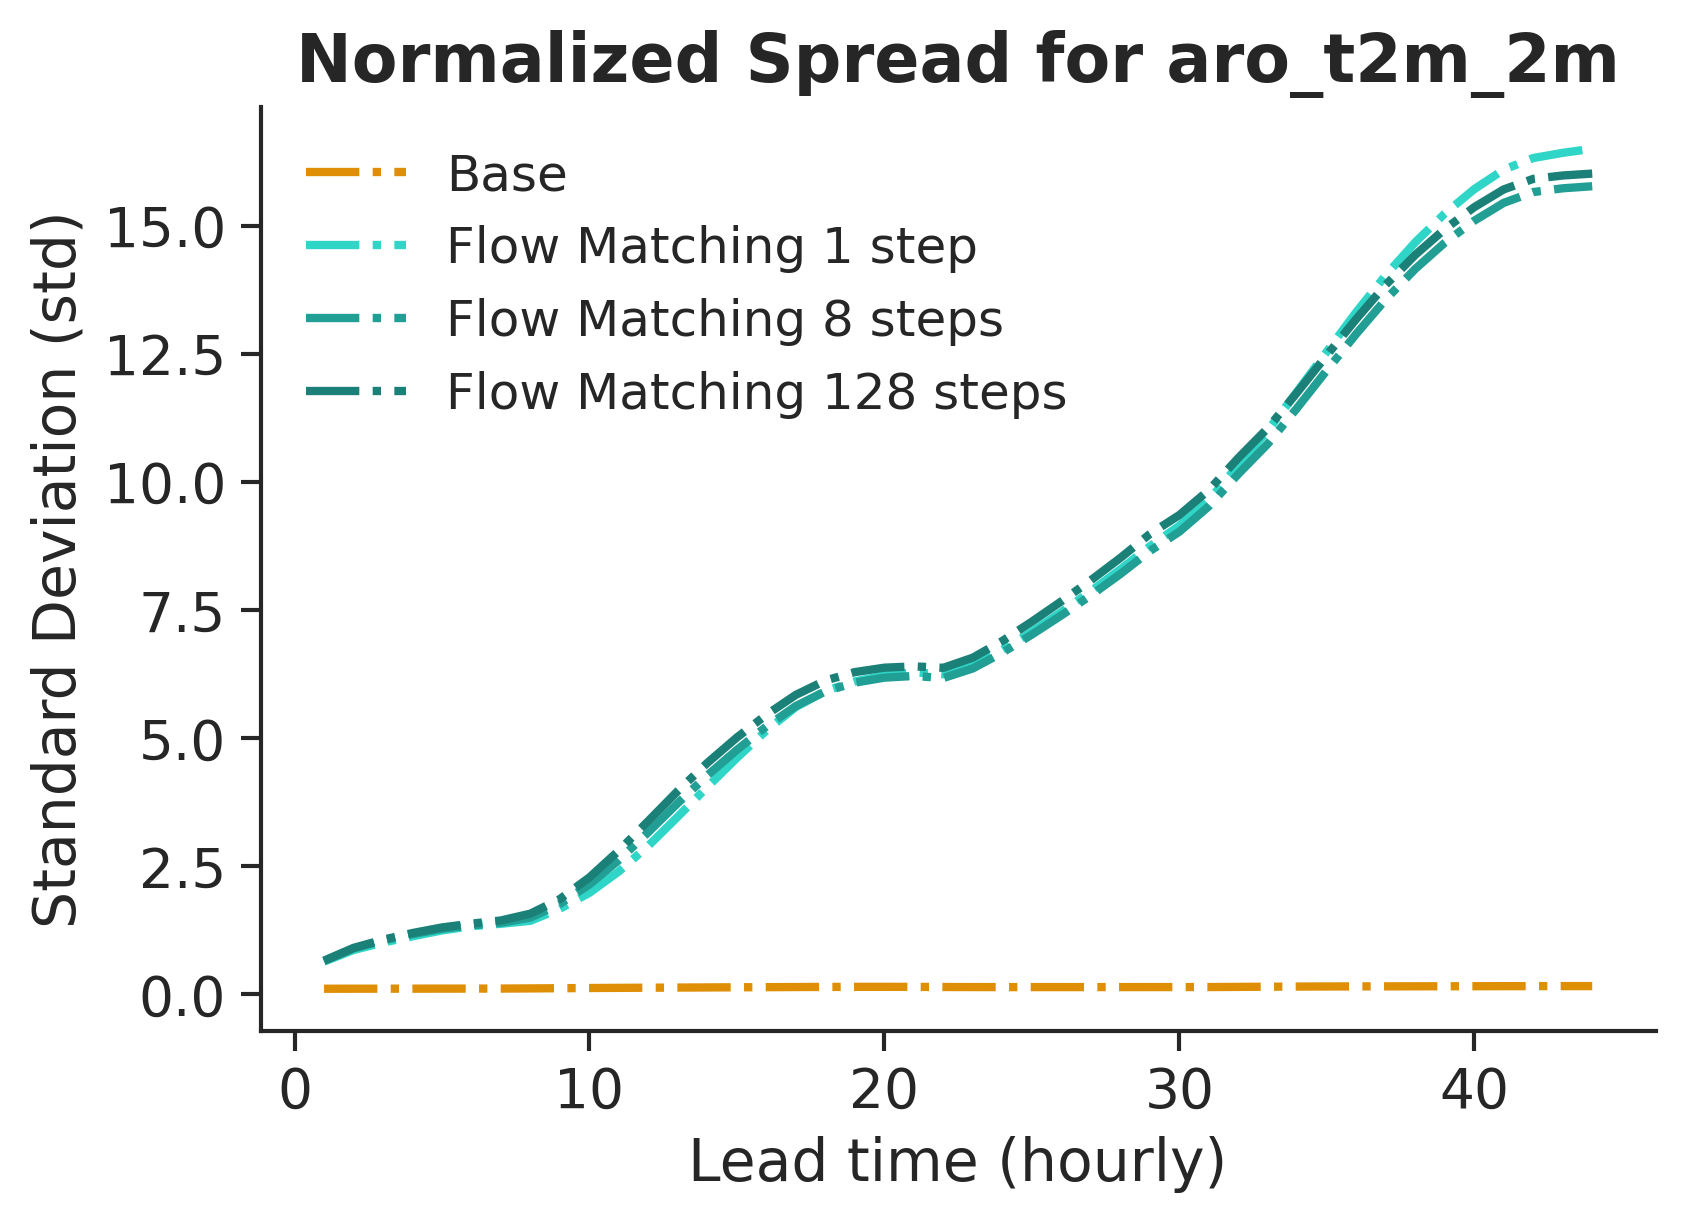

In [75]:
# Set Seaborn style for professional aesthetics
sns.set_context("paper", font_scale=1.5)
sns.set_style("ticks")

# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

# Create the figure
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)

LTs = np.arange(1, 45, 1)

# Plot with distinct, publication-quality colors and styles

ax.plot(df_base['step'], df_base['value'], label='Base',
        color=palette[1], linestyle='-.', linewidth=2)
# ax.plot(df_forcing['step'], df_forcing['value'], label='Forcing',
#         color=palette[2], linestyle='-.', linewidth=2)
# ax.plot(df_smooth['step'], df_smooth['value'], label='Smooth',
#         color=palette[3], linestyle='-.', linewidth=2)
# ax.plot(df_stoEPA['step'], df_stoEPA['value'], label='Stochastic EPA',
#         color=palette[4], linestyle='-.', linewidth=2)
ax.plot(LTs, value_1, label='Flow Matching 1 step',
        color="#2fd6c7", linestyle='-.', linewidth=2)
ax.plot(LTs, value_8, label='Flow Matching 8 steps',
        color="#229f94", linestyle='-.', linewidth=2)
ax.plot(LTs, value_128, label='Flow Matching 128 steps',
        color="#1b8077", linestyle='-.', linewidth=2)

# Labels and title with LaTeX for better typography
ax.set_xlabel(r'Lead time (hourly)', fontsize=14)
ax.set_ylabel(r'Standard Deviation (std)', fontsize=14)
ax.set_title(r'Normalized Spread for ' + var, fontsize=16, weight='bold')

# Customize legend
ax.legend(frameon=False, fontsize=12)

# Remove top and right borders
sns.despine()

# Save as a high-quality vector image
plt.savefig("normalized_spread_std.pdf", bbox_inches='tight', transparent=True)

# Show the plot
plt.show()

## Spread plots per LTs

In [70]:
var = "t2m_2m"

In [ ]:
log_dir = "/data/base/test_poesy/Test_std_timestep_aro_"+var+"_poesy_refacto_EURW1S40_refacto/"
reader = SummaryReader(log_dir)
df_poesy = reader.scalars

# log_dir = "/data/base/test_poesy/Test_std_timestep_aro_"+var+"_preds"
# reader = SummaryReader(log_dir)
# df_base = reader.scalars

# log_dir = "/data/Unetrpp_crps_8nm_v2/test_poesy/Test_std_timestep_aro_"+var+"_preds"
# reader = SummaryReader(log_dir)
# df_forcing = reader.scalars

# log_dir = "/data/Unetrpp_crps_smooth/test_poesy/Test_std_timestep_aro_"+var+"_preds"
# reader = SummaryReader(log_dir)
# df_smooth = reader.scalars

# log_dir = "/data/Unetrpp_crps_stoEPA/test_poesy/Test_std_timestep_aro_"+var+"_preds"
# reader = SummaryReader(log_dir)
# df_stoEPA = reader.scalars

log_dir = "/data/Unetrpp_FM/test_poesy/Test_std_timestep_aro_"+var+"_preds"
reader = SummaryReader(log_dir)
df_FM1 = reader.scalars

log_dir = "/data/Unetrpp_FM/test_poesy_8steps/Test_std_timestep_aro_"+var+"_preds"
reader = SummaryReader(log_dir)
df_FM8 = reader.scalars

log_dir = "/data/Unetrpp_FM/test_poesy_128steps/Test_std_timestep_aro_"+var+"_preds"
reader = SummaryReader(log_dir)
df_FM128 = reader.scalars

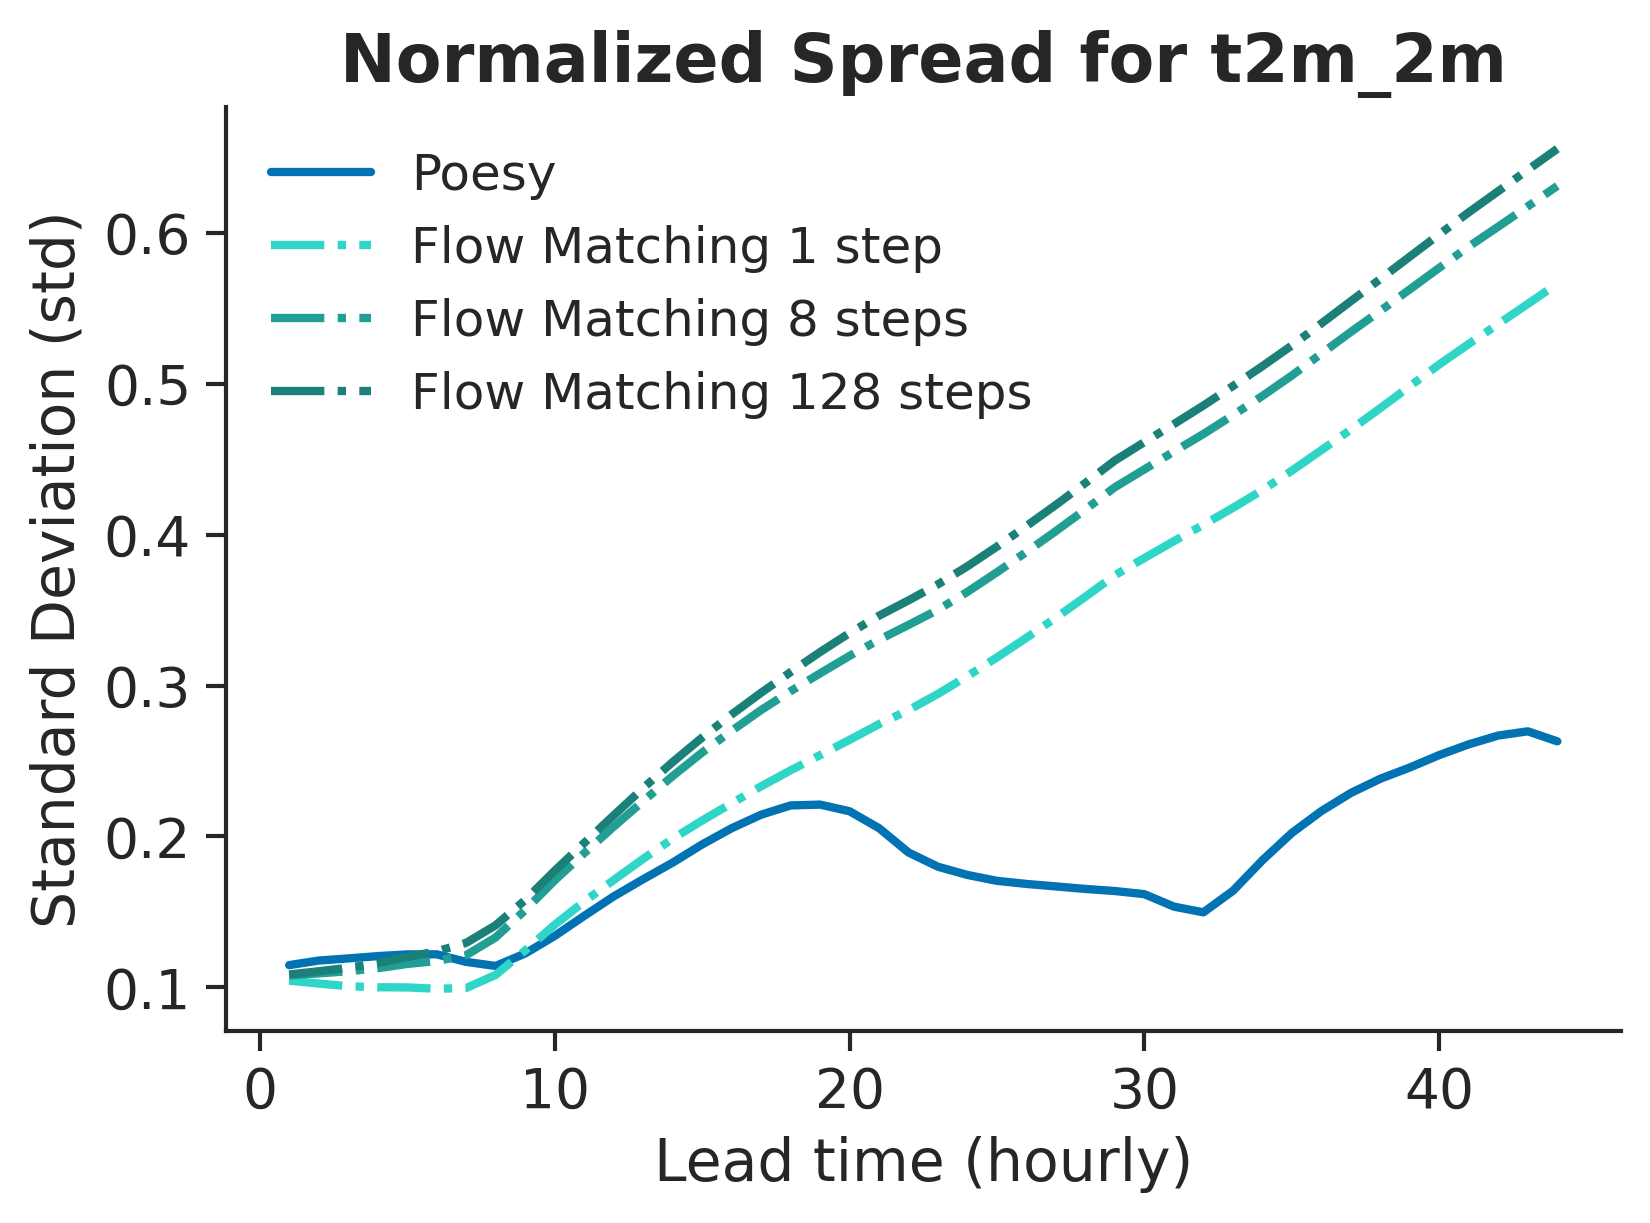

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set Seaborn style for professional aesthetics
sns.set_context("paper", font_scale=1.5)
sns.set_style("ticks")

# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

# Create the figure
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)

# Plot with distinct, publication-quality colors and styles
ax.plot(df_poesy['step'], df_poesy['value'], label='Poesy',
        color=palette[0], linestyle='-', linewidth=2)
# ax.plot(df_base['step'], df_base['value'], label='Base',
#         color=palette[1], linestyle='-.', linewidth=2)
# ax.plot(df_forcing['step'], df_forcing['value'], label='Forcing',
#         color=palette[2], linestyle='-.', linewidth=2)
# ax.plot(df_smooth['step'], df_smooth['value'], label='Smooth',
#         color=palette[3], linestyle='-.', linewidth=2)
# ax.plot(df_stoEPA['step'], df_stoEPA['value'], label='Stochastic EPA',
#         color=palette[4], linestyle='-.', linewidth=2)
ax.plot(df_FM1['step'], df_FM1['value'], label='Flow Matching 1 step',
        color="#2fd6c7", linestyle='-.', linewidth=2)
ax.plot(df_FM8['step'], df_FM8['value'], label='Flow Matching 8 steps',
        color="#229f94", linestyle='-.', linewidth=2)
ax.plot(df_FM128['step'], df_FM128['value'], label='Flow Matching 128 steps',
        color="#1b8077", linestyle='-.', linewidth=2)

# Labels and title with LaTeX for better typography
ax.set_xlabel(r'Lead time (hourly)', fontsize=14)
ax.set_ylabel(r'Standard Deviation (std)', fontsize=14)
ax.set_title(r'Normalized Spread for ' + var, fontsize=16, weight='bold')

# Customize legend
ax.legend(frameon=False, fontsize=12)

# Remove top and right borders
sns.despine()

# Save as a high-quality vector image
plt.savefig("normalized_spread_std.pdf", bbox_inches='tight', transparent=True)

# Show the plot
plt.show()


## Spread Skill Plots

In [12]:
var = "aro_t2m_2m"

In [46]:
poesy_ssp = np.load(f"/data/base/test_poesy/pearo_spread_skill_plot_per_param_{var}_LT_0-10.npy")

# base_ssp = np.load(f"/data/base/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

# forcing_ssp = np.load(f"/data/Unetrpp_crps_8nm_v2/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

# smooth_ssp = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

# stoEPA_ssp = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

FM_ssp = np.load(f"/data/Unetrpp_FM/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy") 

FM8_ssp = np.load(f"/data/Unetrpp_FM/test_poesy_8steps/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

FM128_ssp = np.load(f"/data/Unetrpp_FM/test_poesy_128steps/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

In [ ]:
# poesy_ssp = np.load(f"/data/base/test_poesy/pearo_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# base_ssp = np.load(f"/data/base/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# forcing_ssp = np.load(f"/data/Unetrpp_crps_8nm_v2/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# smooth_ssp = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# stoEPA_ssp = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# FM_ssp = np.load(f"/data/Unetrpp_FM/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy") 

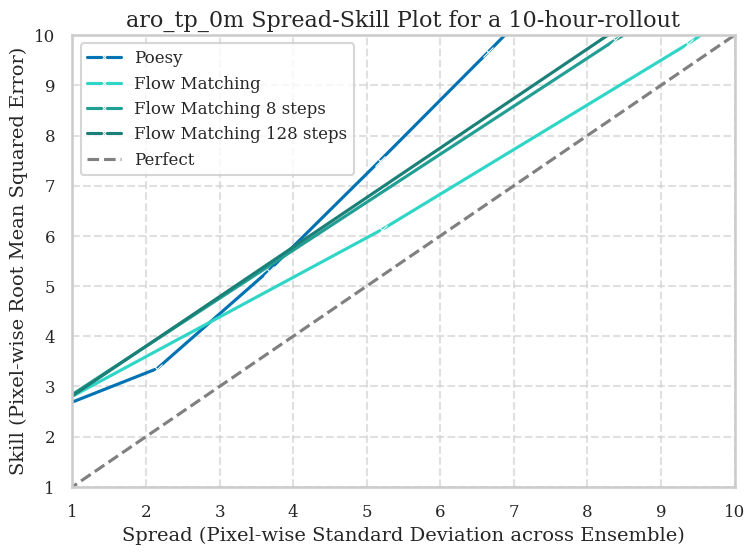

In [47]:
sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,  # Set to True if LaTeX is installed
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})
plt.figure(figsize=(8, 6))
sns.lineplot(x=poesy_ssp[0], y=poesy_ssp[1], marker="x", markersize=7, label="Poesy", color=palette[0])
# sns.lineplot(x=base_ssp[0], y=base_ssp[1], marker="x", markersize=7, label="Base", color=palette[1])
# sns.lineplot(x=forcing_ssp[0], y=forcing_ssp[1], marker="x", markersize=7, label="Forcing", color=palette[2])
# sns.lineplot(x=smooth_ssp[0], y=smooth_ssp[1], marker="x", markersize=7, label="Smooth", color=palette[3])
# sns.lineplot(x=stoEPA_ssp[0], y=stoEPA_ssp[1], marker="x", markersize=7, label="Stochastic EPA", color=palette[4])
sns.lineplot(x=FM_ssp[0], y=FM_ssp[1], marker="x", markersize=7, label="Flow Matching", color="#2fd6c7")
sns.lineplot(x=FM8_ssp[0], y=FM8_ssp[1], marker="x", markersize=7, label="Flow Matching 8 steps", color="#229f94")
sns.lineplot(x=FM128_ssp[0], y=FM128_ssp[1], marker="x", markersize=7, label="Flow Matching 128 steps", color="#1b8077")

# Add perfect line y=x
x = np.linspace(0, 10, 100)
y = x
plt.plot(x, y, color="grey", linestyle="--", label="Perfect")

plt.xlabel("Spread (Pixel-wise Standard Deviation across Ensemble)")
plt.ylabel("Skill (Pixel-wise Root Mean Squared Error)")
plt.title(var+" Spread-Skill Plot for a 10-hour-rollout")
plt.grid(True, linestyle="--", alpha=0.6)
plt.xlim(1, 10)
plt.ylim(1, 10)
plt.legend()
plt.tight_layout()
plt.show()


## Spread Error Ratio 

In [52]:
var = "aro_z_500hpa"

In [53]:
poesy_rse = np.load(f"/data/base/test_poesy/pearo_spread_error_ratio_plot_per_param_{var}.npy")

# base_rse = np.load(f"/data/base/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")

# forcing_rse = np.load(f"/data/Unetrpp_crps_8nm_v2/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")

# smooth_rse = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")

# stoEPA_rse = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")

FM_rse = np.load(f"/data/Unetrpp_FM/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")
FM8_rse = np.load(f"/data/Unetrpp_FM/test_poesy_8steps/preds_spread_error_ratio_plot_per_param_{var}.npy")
FM128_rse = np.load(f"/data/Unetrpp_FM/test_poesy_128steps/preds_spread_error_ratio_plot_per_param_{var}.npy")

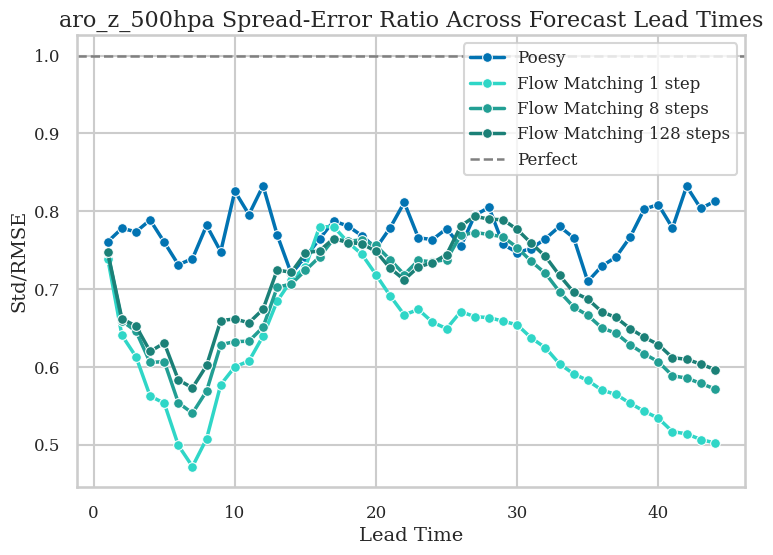

In [54]:
sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,  # Set to True if LaTeX is installed
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

lead_times = np.arange(1, poesy_rse.shape[0] + 1)
plt.figure(figsize=(8, 6))
sns.lineplot(x=lead_times, y=poesy_rse, marker="o", markersize=7, label="Poesy", linewidth=2.5, color=palette[0])
# sns.lineplot(x=lead_times, y=base_rse, marker="o", markersize=7, label="Base", linewidth=2.5, color=palette[1])
# sns.lineplot(x=lead_times, y=forcing_rse, marker="o", markersize=7, label="Forcing", linewidth=2.5, color=palette[2])
# sns.lineplot(x=lead_times, y=smooth_rse, marker="o", markersize=7, label="Smooth", linewidth=2.5, color=palette[3])
# sns.lineplot(x=lead_times, y=stoEPA_rse, marker="o", markersize=7, label="Stochastic EPA", linewidth=2.5, color=palette[4])
sns.lineplot(x=lead_times, y=FM_rse, marker="o", markersize=7, label="Flow Matching 1 step", linewidth=2.5, color="#2fd6c7")
sns.lineplot(x=lead_times, y=FM8_rse, marker="o", markersize=7, label="Flow Matching 8 steps", linewidth=2.5, color="#229f94")
sns.lineplot(x=lead_times, y=FM128_rse, marker="o", markersize=7, label="Flow Matching 128 steps", linewidth=2.5, color="#1b8077")

# Add perfect ratio reference line
plt.axhline(y=1, color="grey", linestyle="--", linewidth=1.8, label="Perfect")

# Labels and title
plt.xlabel("Lead Time")
plt.ylabel("Std/RMSE")
plt.title(f"{var} Spread-Error Ratio Across Forecast Lead Times")
plt.legend(loc="best", frameon=True)

# Tight layout and publication-ready formatting
plt.tight_layout()
plt.show()

## CRPS

In [55]:
poesy_crps = np.load(f"/data/base/test_poesy/pearo_crps_plot_per_param_{var}.npy")

# base_crps = np.load(f"/data/base/test_poesy/preds_crps_plot_per_param_{var}.npy")

# forcing_crps = np.load(f"/data/Unetrpp_crps_8nm_v2/test_poesy/preds_crps_plot_per_param_{var}.npy")

# smooth_crps = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/preds_crps_plot_per_param_{var}.npy")

# stoEPA_crps = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/preds_crps_plot_per_param_{var}.npy")

FM_crps = np.load(f"/data/Unetrpp_FM/test_poesy/preds_crps_plot_per_param_{var}.npy")
FM8_crps = np.load(f"/data/Unetrpp_FM/test_poesy_8steps/preds_crps_plot_per_param_{var}.npy")
FM128_crps = np.load(f"/data/Unetrpp_FM/test_poesy_128steps/preds_crps_plot_per_param_{var}.npy")

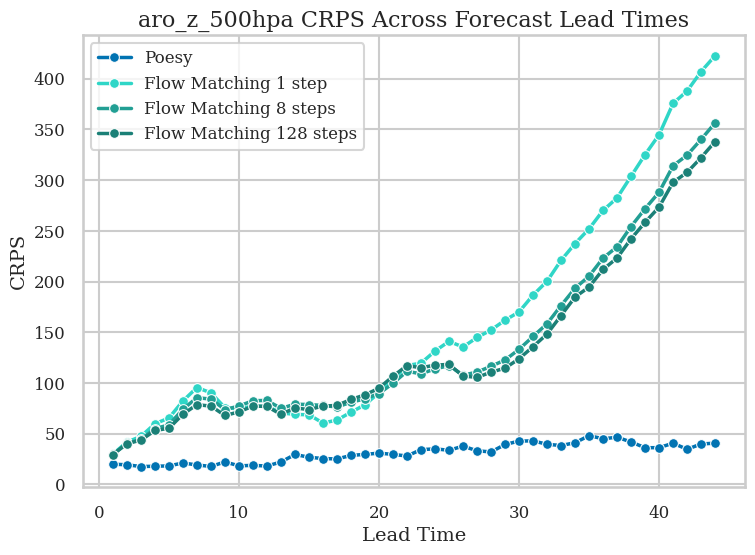

In [56]:
sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

lead_times = np.arange(1, poesy_crps.shape[0] + 1)
plt.figure(figsize=(8, 6))
sns.lineplot(x=lead_times, y=poesy_crps, marker="o", markersize=7, label="Poesy", linewidth=2.5, color=palette[0])
# sns.lineplot(x=lead_times, y=base_crps, marker="o", markersize=7, label="Base", linewidth=2.5, color=palette[1])
# sns.lineplot(x=lead_times, y=forcing_crps, marker="o", markersize=7, label="Forcing", linewidth=2.5, color=palette[2])
# sns.lineplot(x=lead_times, y=smooth_crps, marker="o", markersize=7, label="Smooth", linewidth=2.5, color=palette[3])
# sns.lineplot(x=lead_times, y=stoEPA_crps, marker="o", markersize=7, label="Stochastic EPA", linewidth=2.5, color=palette[4])
sns.lineplot(x=lead_times, y=FM_crps, marker="o", markersize=7, label="Flow Matching 1 step", linewidth=2.5, color="#2fd6c7")
sns.lineplot(x=lead_times, y=FM8_crps, marker="o", markersize=7, label="Flow Matching 8 steps", linewidth=2.5, color="#229f94")
sns.lineplot(x=lead_times, y=FM128_crps, marker="o", markersize=7, label="Flow Matching 128 steps", linewidth=2.5, color="#1b8077")

# Labels and title
plt.xlabel("Lead Time")
plt.ylabel("CRPS")
plt.title(f"{var} CRPS Across Forecast Lead Times")
plt.legend(loc="best", frameon=True)
plt.tight_layout()
plt.show()